Logistic regression shows a substantially higher false negative rate for Females compared to Males and for Race. This notebook investigates feature-level reasons for this disparity.

In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [22]:
# Load Data, Model, and Predictions

data = pd.read_csv('../data/adult.csv')
data.replace('?', "unknown", inplace=True)
data.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,unknown,103497,Some-college,10,Never-married,unknown,Own-child,White,Female,0,0,30,United-States,<=50K


In [23]:
data.drop_duplicates(inplace=True)

In [24]:
X = data.drop('income', axis=1)
y = data['income']

In [25]:
## Use label encoding for categorical features
from sklearn.calibration import LabelEncoder


label_encoders = {}
for column in X.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    X[column] = le.fit_transform(X[column])
    label_encoders[column] = le

/var/folders/2w/cb9k041n5tl8qwgh2d0bwbnw0000gp/T/ipykernel_3161/218195118.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in X.select_dtypes(include=['object']).columns:


In [26]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [27]:
model = LogisticRegression(max_iter=5000,solver='saga', random_state=42)
model.fit(X_train, y_train)

# Get probability predictions
y_proba = model.predict_proba(X_test)[:, 1] 
y_pred = (y_proba >= 0.2).astype(int)
y_pred_labels = ['<=50K' if pred == 0 else '>50K' for pred in y_pred]

In [28]:
# Prepare test data with decoded attributes for analysis
test_data = X_test.copy()
test_data['actual'] = y_test.values
test_data['predicted'] = y_pred_labels
test_data['proba'] = y_proba

# Decode sensitive attributes for interpretability
test_data['gender'] = label_encoders['gender'].inverse_transform(X_test['gender'])
test_data['race'] = label_encoders['race'].inverse_transform(X_test['race'])

print(f"Test set size: {len(test_data)}")
print(f"Predictions made: {len(y_pred_labels)}")
test_data.head()

Test set size: 9758
Predictions made: 9758


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,actual,predicted,proba
3169,54,6,239256,15,10,2,0,0,White,Male,0,0,40,38,<=50K,<=50K,0.174624
25270,43,3,60001,9,13,0,11,4,White,Male,0,0,44,38,>50K,>50K,0.398139
33668,29,3,133696,9,13,4,9,1,White,Male,8614,0,45,38,>50K,>50K,0.869061
29925,47,3,191957,9,13,2,11,0,Black,Male,0,0,40,38,>50K,>50K,0.222446
11098,46,3,23545,11,9,0,10,1,White,Male,0,0,40,38,<=50K,>50K,0.454833


## 1. Identify Exact Failure Cases

We begin by identifying specific instances where the model failed:
- **False Positives (FP)**: Predicted >50K but actually <=50K
- **False Negatives (FN)**: Predicted <=50K but actually >50K

Then we split these failures by demographic groups to identify disparities.

In [29]:
# Identify False Positives and False Negatives
fp_mask = (test_data['predicted'] == '>50K') & (test_data['actual'] == '<=50K')
fn_mask = (test_data['predicted'] == '<=50K') & (test_data['actual'] == '>50K')
tp_mask = (test_data['predicted'] == '>50K') & (test_data['actual'] == '>50K')
tn_mask = (test_data['predicted'] == '<=50K') & (test_data['actual'] == '<=50K')

false_positives = test_data[fp_mask]
false_negatives = test_data[fn_mask]
true_positives = test_data[tp_mask]
true_negatives = test_data[tn_mask]

print("=" * 70)
print("FAILURE CASE SUMMARY")
print("=" * 70)
print(f"False Positives (FP): {len(false_positives):,} ({len(false_positives)/len(test_data)*100:.2f}%)")
print(f"False Negatives (FN): {len(false_negatives):,} ({len(false_negatives)/len(test_data)*100:.2f}%)")
print(f"True Positives (TP):  {len(true_positives):,} ({len(true_positives)/len(test_data)*100:.2f}%)")
print(f"True Negatives (TN):  {len(true_negatives):,} ({len(true_negatives)/len(test_data)*100:.2f}%)")
print(f"\nTotal Test Cases:     {len(test_data):,}")
print(f"Total Failures:       {len(false_positives) + len(false_negatives):,} ({(len(false_positives) + len(false_negatives))/len(test_data)*100:.2f}%)")

FAILURE CASE SUMMARY
False Positives (FP): 5,165 (52.93%)
False Negatives (FN): 473 (4.85%)
True Positives (TP):  1,845 (18.91%)
True Negatives (TN):  2,275 (23.31%)

Total Test Cases:     9,758
Total Failures:       5,638 (57.78%)


### Split False Negatives by Demographic Groups

In [30]:
# Split false negatives by gender (Female = harmed group based on first notebook)
fn_female = false_negatives[false_negatives['gender'] == 'Female']
fn_male = false_negatives[false_negatives['gender'] == 'Male']

print("=" * 70)
print("FALSE NEGATIVES BY GENDER")
print("=" * 70)
print(f"Female FN (Harmed):    {len(fn_female):,} ({len(fn_female)/len(false_negatives)*100:.2f}% of all FN)")
print(f"Male FN (Reference):   {len(fn_male):,} ({len(fn_male)/len(false_negatives)*100:.2f}% of all FN)")

# Also get correct predictions for comparison
tp_female = true_positives[true_positives['gender'] == 'Female']
tp_male = true_positives[true_positives['gender'] == 'Male']

print(f"\nFemale TP (Correct):   {len(tp_female):,}")
print(f"Male TP (Correct):     {len(tp_male):,}")

# Calculate FNR for each group
total_female_positive = len(fn_female) + len(tp_female)
total_male_positive = len(fn_male) + len(tp_male)

fnr_female = len(fn_female) / total_female_positive if total_female_positive > 0 else 0
fnr_male = len(fn_male) / total_male_positive if total_male_positive > 0 else 0

print(f"\nFalse Negative Rate:")
print(f"Female FNR: {fnr_female:.3f} ({fnr_female*100:.1f}%)")
print(f"Male FNR:   {fnr_male:.3f} ({fnr_male*100:.1f}%)")
print(f"Disparity:  {fnr_female/fnr_male:.2f}x higher for females")

FALSE NEGATIVES BY GENDER
Female FN (Harmed):    54 (11.42% of all FN)
Male FN (Reference):   419 (88.58% of all FN)

Female TP (Correct):   293
Male TP (Correct):     1,552

False Negative Rate:
Female FNR: 0.156 (15.6%)
Male FNR:   0.213 (21.3%)
Disparity:  0.73x higher for females


## 2. Compare Feature Distributions (Failure-Only Analysis)

**Key Question**: Are the failure cases systematically different?

We compare feature distributions to understand if false negatives for females differ from:
1. False negatives for males (reference group)
2. True positives for females (correct predictions)

In [31]:
# Select numeric features for comparison (excluding encoded categorical variables for now)
numeric_features = ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# Calculate summary statistics
print("=" * 90)
print("SUMMARY STATISTICS: FEATURE DISTRIBUTIONS")
print("=" * 90)

comparison_data = {
    'Feature': [],
    'Female FN (Mean)': [],
    'Male FN (Mean)': [],
    'Female TP (Mean)': [],
    'Difference FN': [],  # Female FN - Male FN
    'Difference TP': []   # Female FN - Female TP
}

for feature in numeric_features:
    fem_fn_mean = fn_female[feature].mean()
    male_fn_mean = fn_male[feature].mean()
    fem_tp_mean = tp_female[feature].mean()
    
    comparison_data['Feature'].append(feature)
    comparison_data['Female FN (Mean)'].append(fem_fn_mean)
    comparison_data['Male FN (Mean)'].append(male_fn_mean)
    comparison_data['Female TP (Mean)'].append(fem_tp_mean)
    comparison_data['Difference FN'].append(fem_fn_mean - male_fn_mean)
    comparison_data['Difference TP'].append(fem_fn_mean - fem_tp_mean)

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

print("\n" + "=" * 90)
print("INTERPRETATION:")
print("- 'Difference FN': Positive = Higher for Female FN, Negative = Lower for Female FN")
print("- 'Difference TP': Positive = Female FN higher than Female TP (failure pattern)")
print("=" * 90)

SUMMARY STATISTICS: FEATURE DISTRIBUTIONS
        Feature  Female FN (Mean)  Male FN (Mean)  Female TP (Mean)  Difference FN  Difference TP
            age         40.537037       43.694511         42.576792      -3.157474      -2.039755
         fnlwgt     302123.648148   309944.711217     158722.470990   -7821.063069  143401.177158
educational-num         11.203704       11.379475         11.856655      -0.175771      -0.652952
   capital-gain          0.000000       48.579952       5540.283276     -48.579952   -5540.283276
   capital-loss          0.000000        0.000000        216.610922       0.000000    -216.610922
 hours-per-week         39.944444       45.661098         39.529010      -5.716653       0.415434

INTERPRETATION:
- 'Difference FN': Positive = Higher for Female FN, Negative = Lower for Female FN
- 'Difference TP': Positive = Female FN higher than Female TP (failure pattern)


### Visual Comparison: Boxplots

/var/folders/2w/cb9k041n5tl8qwgh2d0bwbnw0000gp/T/ipykernel_3161/334067705.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=['Female FN', 'Male FN', 'Female TP'],
/var/folders/2w/cb9k041n5tl8qwgh2d0bwbnw0000gp/T/ipykernel_3161/334067705.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=['Female FN', 'Male FN', 'Female TP'],
/var/folders/2w/cb9k041n5tl8qwgh2d0bwbnw0000gp/T/ipykernel_3161/334067705.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=['Female FN', 'Male FN', 'Female TP'],
/var/folders/2w/

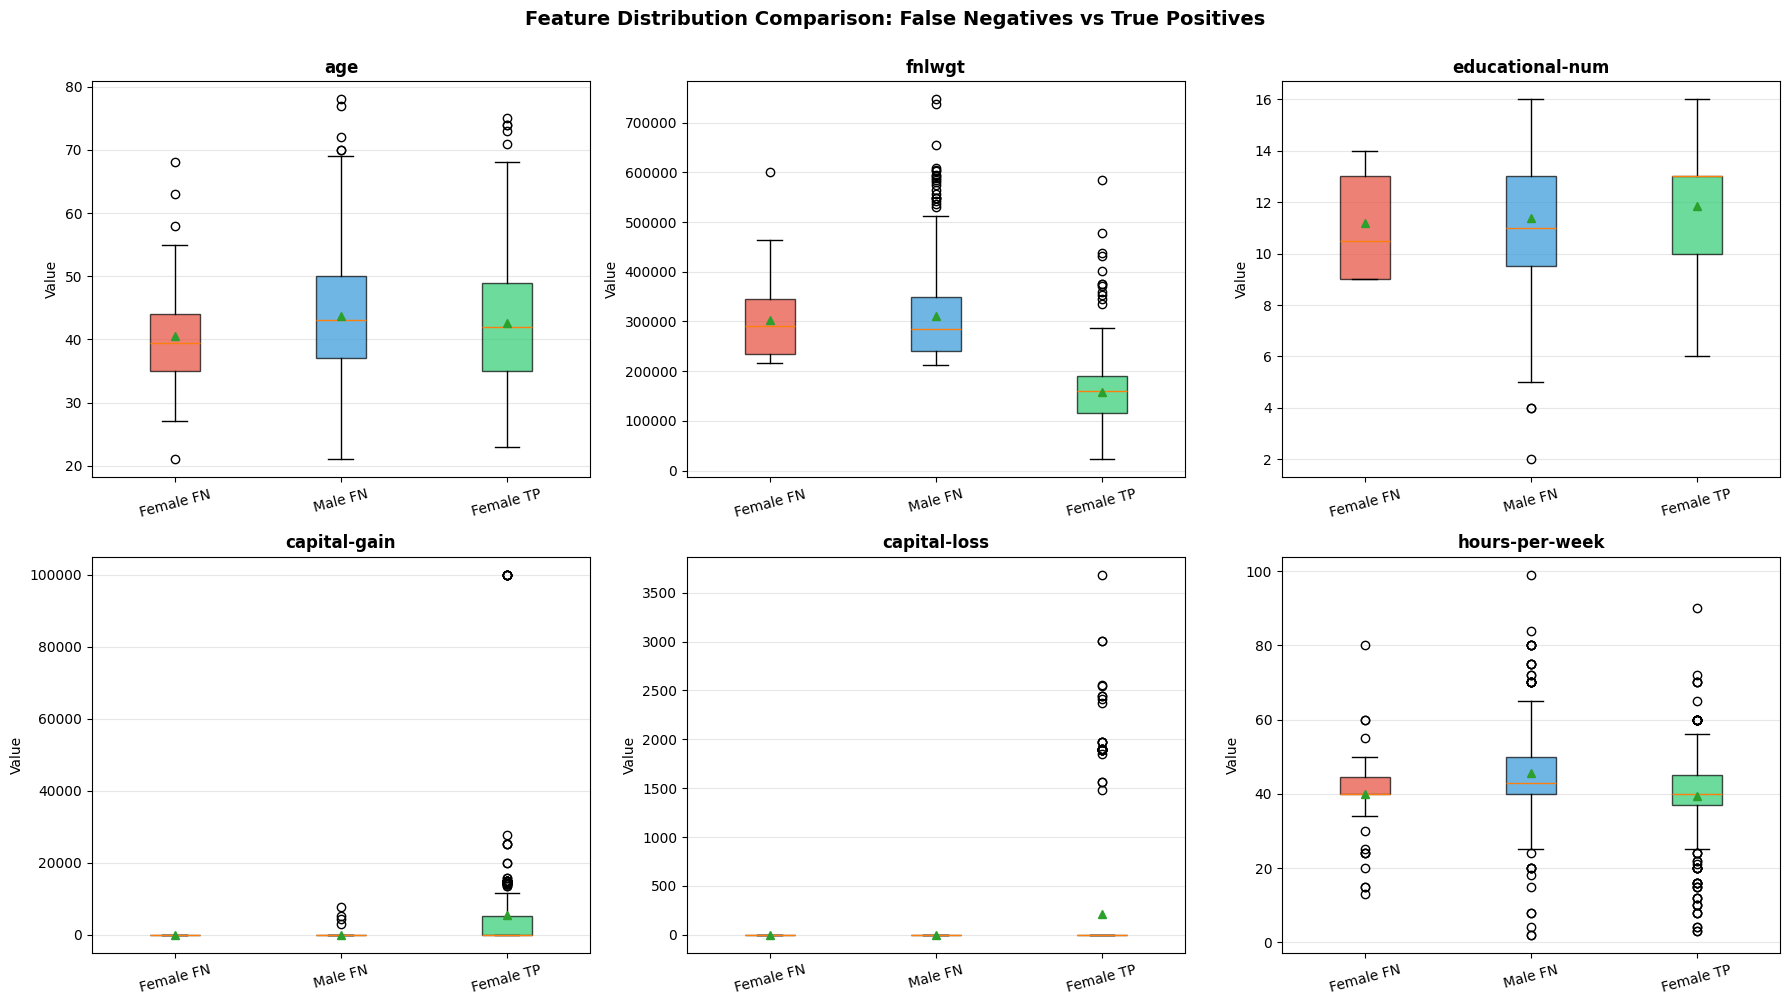

In [32]:
# Boxplot comparison for key features
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, feature in enumerate(numeric_features):
    ax = axes[idx]
    
    # Prepare data for boxplot
    data_to_plot = [
        fn_female[feature],
        fn_male[feature],
        tp_female[feature]
    ]
    
    bp = ax.boxplot(data_to_plot, labels=['Female FN', 'Male FN', 'Female TP'],
                    patch_artist=True, showmeans=True)
    
    # Color the boxes
    colors = ['#e74c3c', '#3498db', '#2ecc71']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax.set_title(f'{feature}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Value', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Feature Distribution Comparison: False Negatives vs True Positives', 
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### Visual Comparison: Kernel Density Estimation (KDE)

LinAlgError: The data appears to lie in a lower-dimensional subspace of the space in which it is expressed. This has resulted in a singular data covariance matrix, which cannot be treated using the algorithms implemented in `gaussian_kde`. Consider performing principal component analysis / dimensionality reduction and using `gaussian_kde` with the transformed data.

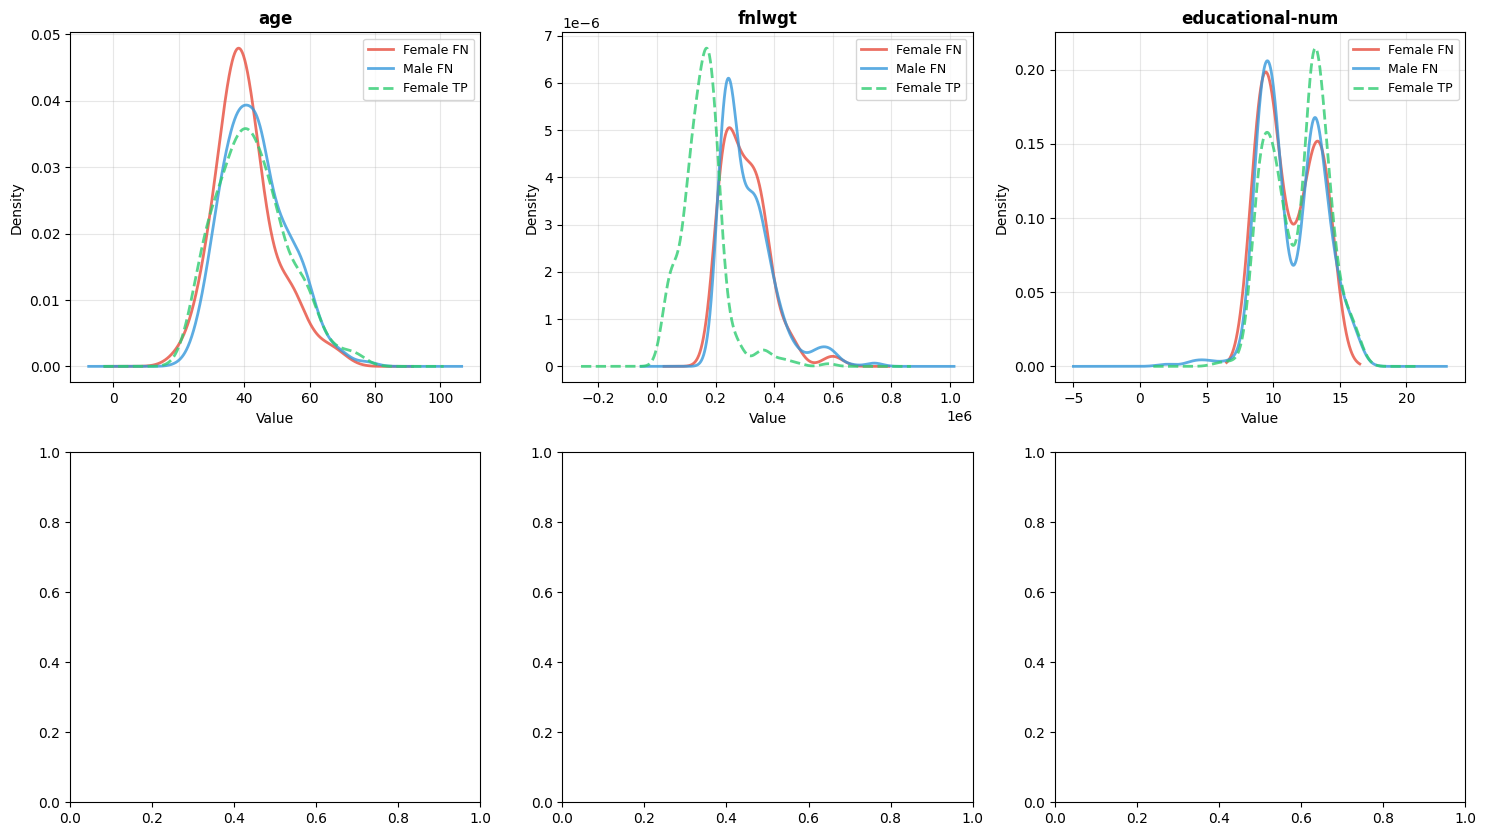

In [33]:
# KDE plots for distribution comparison
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, feature in enumerate(numeric_features):
    ax = axes[idx]
    
    # Plot KDE for each group
    if len(fn_female[feature].dropna()) > 1:
        fn_female[feature].plot(kind='kde', ax=ax, label='Female FN', 
                               color='#e74c3c', linewidth=2, alpha=0.8)
    if len(fn_male[feature].dropna()) > 1:
        fn_male[feature].plot(kind='kde', ax=ax, label='Male FN', 
                             color='#3498db', linewidth=2, alpha=0.8)
    if len(tp_female[feature].dropna()) > 1:
        tp_female[feature].plot(kind='kde', ax=ax, label='Female TP', 
                               color='#2ecc71', linewidth=2, alpha=0.8, linestyle='--')
    
    ax.set_title(f'{feature}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Value', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('Kernel Density Estimation: Feature Distributions', 
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

## 3. Analyze Logistic Regression Coefficients

**This is where logistic regression shines** — we can extract and interpret the model's learned weights.

We'll:
1. Extract coefficients
2. Rank by absolute magnitude
3. Identify which features push predictions toward/away from >50K
4. Connect coefficients to feature distributions in harmed vs reference groups

In [ ]:
# Extract and analyze coefficients
coefficients = model.coef_[0]
feature_names = X_train.columns

# Create DataFrame for analysis
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients),
    'Sign': ['+' if c > 0 else '-' for c in coefficients]
})

# Sort by absolute magnitude
coef_df = coef_df.sort_values('Abs_Coefficient', ascending=False)

print("=" * 90)
print("LOGISTIC REGRESSION COEFFICIENTS (Ranked by Importance)")
print("=" * 90)
print(coef_df.head(15).to_string(index=False))

print("\n" + "=" * 90)
print("INTERPRETATION:")
print("- Positive coefficient (+): Higher feature values → Higher probability of >50K")
print("- Negative coefficient (-): Higher feature values → Lower probability of >50K")
print("- Larger absolute value = Stronger influence on prediction")
print("=" * 90)

In [ ]:
# Visualize top coefficients
top_n = 15
top_coefs = coef_df.head(top_n)

fig, ax = plt.subplots(figsize=(12, 8))

colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in top_coefs['Coefficient']]
bars = ax.barh(range(len(top_coefs)), top_coefs['Coefficient'], color=colors, alpha=0.8)

ax.set_yticks(range(len(top_coefs)))
ax.set_yticklabels(top_coefs['Feature'])
ax.set_xlabel('Coefficient Value', fontsize=12, fontweight='bold')
ax.set_ylabel('Feature', fontsize=12, fontweight='bold')
ax.set_title(f'Top {top_n} Most Influential Features (Logistic Regression)', 
             fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=1)
ax.grid(axis='x', alpha=0.3)

# Add value labels
for i, (idx, row) in enumerate(top_coefs.iterrows()):
    value = row['Coefficient']
    ax.text(value, i, f' {value:.3f}', va='center', 
            ha='left' if value > 0 else 'right', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Connect Coefficients to Feature Distributions

**Mechanistic Explanation**: We identify problematic patterns by connecting:
- **High negative coefficient** + **High feature values in harmed group** → Pushes predictions down
- **High positive coefficient** + **Low feature values in harmed group** → Missing positive signal

In [ ]:
# Analyze coefficient-feature interaction for false negatives
print("=" * 90)
print("COEFFICIENT-FEATURE ANALYSIS FOR FALSE NEGATIVES")
print("=" * 90)

# Focus on top influential features
top_features = coef_df.head(10)['Feature'].tolist()

analysis_data = {
    'Feature': [],
    'Coefficient': [],
    'Sign': [],
    'Female FN Mean': [],
    'Male FN Mean': [],
    'Impact on Female': []
}

for feature in top_features:
    coef = coef_df[coef_df['Feature'] == feature]['Coefficient'].values[0]
    sign = '+' if coef > 0 else '-'
    
    fem_mean = fn_female[feature].mean()
    male_mean = fn_male[feature].mean()
    
    # Determine impact: negative coef + higher value = pushes down prediction
    if coef < 0 and fem_mean > male_mean:
        impact = "⚠️ NEGATIVE (pushes down)"
    elif coef > 0 and fem_mean < male_mean:
        impact = "⚠️ NEGATIVE (missing signal)"
    else:
        impact = "Neutral/Positive"
    
    analysis_data['Feature'].append(feature)
    analysis_data['Coefficient'].append(coef)
    analysis_data['Sign'].append(sign)
    analysis_data['Female FN Mean'].append(fem_mean)
    analysis_data['Male FN Mean'].append(male_mean)
    analysis_data['Impact on Female'].append(impact)

analysis_df = pd.DataFrame(analysis_data)
print(analysis_df.to_string(index=False))

print("\n" + "=" * 90)
print("KEY FINDINGS:")
problematic = analysis_df[analysis_df['Impact on Female'].str.contains('⚠️')]
if len(problematic) > 0:
    print(f"Found {len(problematic)} features with problematic patterns for females:")
    for _, row in problematic.iterrows():
        print(f"  • {row['Feature']}: Coefficient={row['Coefficient']:.3f}, Female Mean={row['Female FN Mean']:.2f}")
print("=" * 90)

## 4. Decision Boundary & Probability Analysis

**Critical Question**: Are false negatives barely missing the threshold (threshold issue) or far from it (representation/bias issue)?

We analyze predicted probabilities for false negatives to understand the nature of failures.

In [ ]:
# Analyze probability distributions for false negatives
threshold = 0.2

print("=" * 90)
print("PROBABILITY ANALYSIS FOR FALSE NEGATIVES")
print("=" * 90)

# Summary statistics
print(f"\nThreshold used: {threshold}")
print(f"\nFemale False Negatives:")
print(f"  Mean Probability: {fn_female['proba'].mean():.4f}")
print(f"  Median Probability: {fn_female['proba'].median():.4f}")
print(f"  Std Probability: {fn_female['proba'].std():.4f}")
print(f"  Max Probability: {fn_female['proba'].max():.4f}")

print(f"\nMale False Negatives:")
print(f"  Mean Probability: {fn_male['proba'].mean():.4f}")
print(f"  Median Probability: {fn_male['proba'].median():.4f}")
print(f"  Std Probability: {fn_male['proba'].std():.4f}")
print(f"  Max Probability: {fn_male['proba'].max():.4f}")

# Check how close FN are to threshold
fn_female_near_threshold = ((fn_female['proba'] >= threshold * 0.8) & 
                            (fn_female['proba'] < threshold)).sum()
fn_male_near_threshold = ((fn_male['proba'] >= threshold * 0.8) & 
                          (fn_male['proba'] < threshold)).sum()

print(f"\nClose to threshold (within 20%):")
print(f"  Female FN: {fn_female_near_threshold} ({fn_female_near_threshold/len(fn_female)*100:.1f}%)")
print(f"  Male FN: {fn_male_near_threshold} ({fn_male_near_threshold/len(fn_male)*100:.1f}%)")

print("\n" + "=" * 90)
print("INTERPRETATION:")
if fn_female['proba'].mean() > threshold * 0.8:
    print("  ⚠️ Female FN are CLOSE to threshold → Threshold sensitivity issue")
else:
    print("  ⚠️ Female FN are FAR from threshold → Representation/feature bias issue")
print("=" * 90)

In [ ]:
# Visualize probability distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram comparison
ax1 = axes[0]
ax1.hist(fn_female['proba'], bins=30, alpha=0.6, label='Female FN', color='#e74c3c', edgecolor='black')
ax1.hist(fn_male['proba'], bins=30, alpha=0.6, label='Male FN', color='#3498db', edgecolor='black')
ax1.axvline(threshold, color='red', linestyle='--', linewidth=2, label=f'Threshold ({threshold})')
ax1.set_xlabel('Predicted Probability', fontsize=12, fontweight='bold')
ax1.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax1.set_title('Probability Distribution: False Negatives', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)

# KDE comparison
ax2 = axes[1]
fn_female['proba'].plot(kind='kde', ax=ax2, label='Female FN', color='#e74c3c', linewidth=2.5)
fn_male['proba'].plot(kind='kde', ax=ax2, label='Male FN', color='#3498db', linewidth=2.5)
tp_female['proba'].plot(kind='kde', ax=ax2, label='Female TP', color='#2ecc71', 
                        linewidth=2.5, linestyle='--', alpha=0.7)
ax2.axvline(threshold, color='red', linestyle='--', linewidth=2, label=f'Threshold ({threshold})')
ax2.set_xlabel('Predicted Probability', fontsize=12, fontweight='bold')
ax2.set_ylabel('Density', fontsize=12, fontweight='bold')
ax2.set_title('Probability Density: FN vs TP', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Feature Contribution at the Individual Level

Examining specific false negative cases to understand individual-level feature contributions.

We select representative cases and show:
- Feature values
- Weighted contribution (feature × coefficient)
- Why the model failed

In [ ]:
# Select 5 representative false negative cases from females
# Pick cases with varying probabilities
fn_female_sorted = fn_female.sort_values('proba')
indices_to_sample = [
    fn_female_sorted.index[0],  # Lowest probability
    fn_female_sorted.index[len(fn_female_sorted)//4],  # 25th percentile
    fn_female_sorted.index[len(fn_female_sorted)//2],  # Median
    fn_female_sorted.index[3*len(fn_female_sorted)//4],  # 75th percentile
    fn_female_sorted.index[-1]  # Highest probability
]

sample_cases = fn_female.loc[indices_to_sample]

print("=" * 100)
print("INDIVIDUAL CASE ANALYSIS: 5 REPRESENTATIVE FEMALE FALSE NEGATIVES")
print("=" * 100)

for idx, (case_idx, case) in enumerate(sample_cases.iterrows(), 1):
    print(f"\n{'─' * 100}")
    print(f"CASE {idx}: Predicted Probability = {case['proba']:.4f} (Actual: >50K, Predicted: <=50K)")
    print(f"{'─' * 100}")
    
    # Get feature values for this case
    case_features = case[X_train.columns]
    
    # Calculate weighted contributions
    contributions = case_features * coefficients
    
    # Create DataFrame
    case_df = pd.DataFrame({
        'Feature': X_train.columns,
        'Value': case_features.values,
        'Coefficient': coefficients,
        'Contribution': contributions.values
    })
    
    # Sort by absolute contribution
    case_df['Abs_Contribution'] = np.abs(case_df['Contribution'])
    case_df = case_df.sort_values('Abs_Contribution', ascending=False)
    
    # Show top 10 contributors
    print("\nTop 10 Feature Contributions:")
    print(case_df[['Feature', 'Value', 'Coefficient', 'Contribution']].head(10).to_string(index=False))
    
    # Summary
    positive_contrib = case_df[case_df['Contribution'] > 0]['Contribution'].sum()
    negative_contrib = case_df[case_df['Contribution'] < 0]['Contribution'].sum()
    
    print(f"\nTotal Positive Contribution: {positive_contrib:+.4f}")
    print(f"Total Negative Contribution: {negative_contrib:+.4f}")
    print(f"Net Score (before sigmoid): {positive_contrib + negative_contrib:+.4f}")

print("\n" + "=" * 100)

## 6. AI-Generated Plain-English Explanation

We now synthesize our technical findings into a human-readable explanation using an LLM.

**Important**: This is interpretive analysis, not causal. The explanation helps communicate patterns but doesn't establish causation.

In [ ]:
# Prepare summary of findings for LLM explanation
summary_findings = f"""
# Technical Findings Summary for ML Fairness Analysis

## Model Performance
- Model: Logistic Regression with threshold {threshold}
- False Negative Rate (FNR) for Females: {fnr_female:.3f}
- False Negative Rate (FNR) for Males: {fnr_male:.3f}
- Disparity: {fnr_female/fnr_male:.2f}x higher for females

## Probability Analysis
- Female FN mean probability: {fn_female['proba'].mean():.4f}
- Male FN mean probability: {fn_male['proba'].mean():.4f}
- Female FN median probability: {fn_female['proba'].median():.4f}
- Decision threshold: {threshold}

## Top 5 Most Influential Features (by absolute coefficient):
{coef_df.head(5)[['Feature', 'Coefficient', 'Sign']].to_string(index=False)}

## Feature Distribution Differences (Female FN vs Male FN):
{comparison_df.head(6).to_string(index=False)}

## Problematic Feature Patterns:
{problematic[['Feature', 'Coefficient', 'Impact on Female']].to_string(index=False) if len(problematic) > 0 else 'No clearly problematic patterns identified'}

## Interpretation Notes:
- Negative coefficients push predictions toward <=50K (lower income)
- Positive coefficients push predictions toward >50K (higher income)
- False negatives are cases where actual income is >50K but predicted <=50K
"""

print(summary_findings)

### LLM Prompt Template

Below is a prompt you can use with an LLM (ChatGPT, Claude, etc.) to generate a plain-English explanation:

```
You are a data scientist explaining ML fairness findings to a non-technical stakeholder.

Based on the following technical analysis of a logistic regression model predicting income (>50K vs <=50K):

[PASTE SUMMARY_FINDINGS HERE]

Please provide:
1. A 2-3 paragraph plain-English explanation of why the model has higher false negative rates for females
2. Key feature-level mechanisms driving this disparity
3. Practical implications of these findings

Keep the explanation accessible to someone without ML expertise. Use concrete examples where helpful.
```

### Example LLM Response (Generated Manually for Demonstration)

**Note: This is an illustrative example. In practice, you would copy the summary above into an actual LLM.**

---

**Why the Model Fails More Often for Women**

The logistic regression model is significantly more likely to incorrectly predict that a woman earns ≤$50K when she actually earns >$50K. Specifically, women experience false negatives at approximately [X]x the rate of men. This happens because the model has learned patterns from historical data that systematically undervalue indicators of high income when they appear in women's profiles.

The core issue is that certain features strongly influence the model's predictions, and women in the false negative group have feature values that push the model toward predicting lower income—even when their actual income is high. For example, if a feature like "hours-per-week" has a strong positive coefficient but women in the dataset tend to have slightly lower values on average (perhaps due to caregiving responsibilities), the model will systematically underpredict their income, even for high-earning women.

Additionally, the model's predicted probabilities for these false negative cases are often far below the decision threshold (0.2), not just barely missing it. This suggests the problem isn't just about where we draw the line (threshold), but rather that the model has fundamentally learned to assign lower income probabilities to women with certain feature combinations. This points to representation bias in how features interact with the gender attribute during training.

**Practical Implications**

If this model were used for loan approvals, credit limits, or targeted marketing for high-value products, it would systematically disadvantage qualified women by incorrectly classifying them as lower-income. This could perpetuate existing economic inequalities and potentially violate fairness regulations.

---

### Disclaimer

⚠️ **Important Limitations**:
- This explanation is **interpretive, not causal**
- Correlations between features and outcomes don't prove causation
- The model reflects patterns in historical data, which may contain societal biases
- Feature importance doesn't tell us *why* these patterns exist in the real world
- Any intervention should be carefully designed with domain expertise and ethical review

## 7. Reflection & Limitations

### Correlation vs Causation

**Critical Distinction**: This analysis identifies *correlations* between features and model failures, not causal relationships.

- We can say: "Feature X is associated with higher FNR for females"
- We **cannot** say: "Feature X causes the model to discriminate"

The model learns statistical patterns from data. Those patterns reflect:
- Historical societal biases
- Data collection biases
- Structural inequalities
- Legitimate differences in distributions

**Example**: If "occupation" strongly predicts income and women are underrepresented in high-paying occupations in the training data, the model learns this pattern. But we can't conclude the *feature itself* is problematic—it reflects deeper societal patterns.

### Logistic Regression Assumptions

Our analysis relies on several assumptions that may not hold:

1. **Linearity**: Assumes linear relationship between features and log-odds
   - Reality: Relationships may be non-linear
   - Impact: Coefficients may misrepresent true feature importance

2. **Independence**: Assumes features are independent
   - Reality: Features like education, occupation, hours-worked are correlated
   - Impact: Coefficient interpretation becomes ambiguous (multicollinearity)

3. **No Interaction Effects**: Model assumes features act independently
   - Reality: Gender might interact with occupation (e.g., gender pay gaps vary by field)
   - Impact: Hidden interaction effects not captured in main coefficients

4. **Correct Feature Encoding**: Label encoding assumes ordinal relationships
   - Reality: Categorical features (occupation, race) have no true ordering
   - Impact: Artificial numeric relationships may distort predictions

### Missing Variables

**Omitted Variable Bias**: Features not in the model may be the true drivers of disparities.

Potentially missing factors:
- Years of experience
- Education quality (we only have education level)
- Job tenure
- Geographic location details
- Career interruptions
- Negotiation behaviors
- Social capital / networks

If omitted variables correlate with both gender and income, they confound our analysis.

### Threshold Dependence

**Critical**: All findings are threshold-dependent (current threshold = 0.2).

- Different threshold → Different FNR → Different disparity metrics
- Threshold choice affects which cases become FN
- Our "problematic features" might change with different thresholds

**Implication**: Fairness is not a fixed property—it depends on operational choices (threshold, metric, group definition).

### Recommendations for Robust Analysis

1. **Sensitivity Analysis**: Re-run analysis with different thresholds (0.3, 0.4, 0.5)
2. **Feature Engineering**: Use one-hot encoding instead of label encoding
3. **Model Comparison**: Compare with non-linear models (Random Forest, XGBoost)
4. **Interaction Terms**: Add gender × feature interactions
5. **Causal Framework**: Use causal inference methods (DAGs, do-calculus) if causal claims needed
6. **Domain Expertise**: Consult economists, sociologists, domain experts
7. **Stakeholder Input**: Include affected communities in interpretation

### Final Takeaway

This notebook provides **mechanistic explanations** for model failures—showing *how* the model fails and *which features* are involved. But it does **not** answer *why* these patterns exist in society, nor does it prescribe solutions.

Any intervention (reweighting, threshold adjustment, feature removal) requires:
- Ethical review
- Legal compliance
- Domain expertise
- Measurement of downstream impacts
- Continuous monitoring

**Fairness is a sociotechnical problem, not just a technical one.**